# **Libraries**
---
The libraries used in the classification workflow are imported: execution time measurement, visualization, data manipulation, synthetic data generation, hyperparameter search with cross-validation, the Random Forest classification model, and the F1 metric.

The `time` library is central to this notebook, because the objective is not only to compare the performance of the models but also the **computational cost** of each hyperparameter selection strategy.

In [1]:
# Utils
# ==============================================================================
import warnings
import time

# Plot
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Data
# ==============================================================================
import pandas as pd
from sklearn.datasets import make_classification

# Model
# ==============================================================================
from sklearn.model_selection import (
    train_test_split,
    ParameterGrid,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

# Metrics
# ==============================================================================
from sklearn.metrics import f1_score

# **Info**
---

**@By:** Steven Bernal

**@Nickname:** Kaiziferr

**@Git:** https://github.com/Kaiziferr

# **Configuration**
---
The global configuration of the run is defined. Warning messages are suppressed to produce cleaner outputs, the seaborn `tab10` color palette is defined for the comparison plots, and the random seed `12354` is set. This seed is used in data generation, the data split, and all models to ensure reproducibility.

In [2]:
warnings.simplefilter("ignore")
paleta = sns.color_palette("tab10").as_hex()
random_seed = 12354

# **Data context**
---
**Project context**

The objective of this project is to demonstrate the use of the **OOB score** (out-of-bag score) in Random Forest as an alternative to cross-validation for hyperparameter selection, now in a **multiclass classification problem with imbalanced classes**. In a Random Forest, each tree is trained on a bootstrap sample of the training set, and the observations left out of that sample (out-of-bag) make it possible to estimate model performance without reserving additional folds.

**Data source**

A synthetic dataset was chosen because it provides a controlled and educational environment, specifically designed to explain the use of the OOB score in Random Forest hyperparameter selection.

Working with real-world datasets usually requires considerable preprocessing effort, such as data cleaning, handling missing values, correcting inconsistencies, and transforming variables. Although these steps are essential in any data science workflow, they are outside the scope of this discussion.

**Objectives**

- Select the hyperparameters of a Random Forest classifier with GridSearchCV and 5-fold cross-validation, using macro F1 as the metric.
- Select the hyperparameters with the OOB score, first with the default accuracy and then with a custom metric (macro F1).
- Compare the strategies on the test set and in terms of **computational cost**, distinguishing the time of each fit from the total search time.

# **Classification**
---

## **Data**
---
The scikit-learn make_classification function is used to generate a multiclass classification problem:

- `1,000` observations and 10 predictor variables are generated: 7 informative variables, 2 redundant variables (linear combinations of the informative ones), and 1 noise variable unrelated to the class.
- 3 classes are defined with target proportions of 0.50, 0.35, and 0.15. The third class is the minority class, which introduces an **imbalance** that affects the choice of metric.
- The class_sep=0.8 parameter controls the separation between classes. A value lower than the default (1.0) produces more overlapping classes and, therefore, a harder problem.
- By default, make_classification randomly reassigns 1% of the labels (flip_y=0.01). This noise cannot be predicted, so no model can correctly classify every new observation.

The imbalance is the reason for using **macro F1**: it calculates the F1 score of each class and averages them with equal weight, so the minority class counts as much as the majority class. Accuracy, in contrast, gives the same weight to every observation and can hide poor performance in the minority class.

In [3]:
X, y = make_classification(
    n_samples = 1000,
    n_features = 10,
    n_informative = 7,
    n_redundant = 2,
    n_classes = 3,
    weights = [0.5, 0.35, 0.15],
    class_sep = 0.8,
    random_state=random_seed
)

The first rows of the predictor variables are displayed to verify their structure.

In [4]:
pd.DataFrame(X).head()

,0,1,2,3,4,5,6,7,8,9
0,-1.994293,-0.973313,0.466511,-0.515801,-0.967409,0.580365,0.491026,-1.403556,-1.121424,-1.452780
1,0.696166,0.178325,-0.318898,-3.402707,-1.793873,-2.312178,-0.302448,-0.104724,-0.445917,0.874871
2,0.625275,-0.937379,-0.648134,2.716655,-1.646116,1.649589,-0.225699,-1.275536,2.087411,-3.970914
3,1.039204,-0.232609,-0.875510,2.659175,-0.753183,1.619898,0.520669,0.753762,1.978488,-2.406901
4,-0.650574,1.549419,-1.053377,-1.470399,-1.207146,0.951660,0.821624,1.351607,0.159333,-1.000345


## **Data split**
---
The dataset is split into training and test sets with train_test_split. 80% of the observations (800) are assigned to the training set, and the remaining 20% (200) are reserved for the final evaluation.

With stratify=y, the split preserves approximately the same class proportions in both subsets as in the full dataset. In an imbalanced problem this matters: without stratification, the minority class could be underrepresented in the test set, and the final evaluation would be less reliable.

As in regression, no separate validation set is created: GridSearchCV cross-validation and the OOB score obtain their estimates from the training set itself. The test set is not involved in any of the searches.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size = 0.8,
    stratify=y,
    random_state = random_seed
)

The class distribution is checked in the full dataset, the training set, and the test set, with the number of observations and the proportion of each class.

In [6]:
class_distribution = pd.DataFrame({
    'total (n)': pd.Series(y).value_counts(),
    'train (n)': pd.Series(y_train).value_counts(),
    'test (n)': pd.Series(y_test).value_counts(),
}).sort_index()
class_distribution['total proportion'] = (class_distribution['total (n)'] / len(y)).round(4)
class_distribution['train proportion'] = (class_distribution['train (n)'] / len(y_train)).round(4)
class_distribution['test proportion'] = (class_distribution['test (n)'] / len(y_test)).round(4)
class_distribution

,total (n),train (n),test (n),total proportion,train proportion,test proportion
0,494,395,99,0.494,0.4938,0.495
1,350,280,70,0.350,0.3500,0.350
2,156,125,31,0.156,0.1562,0.155


The table confirms the imbalance and the effect of stratification:

- The full dataset contains 494 observations of class 0 (49.4%), 350 of class 1 (35.0%), and 156 of class 2 (15.6%). The proportions differ slightly from the defined ones (0.50, 0.35, and 0.15) because of the 1% of randomly reassigned labels (flip_y).
- The training proportions (49.38%, 35.00%, and 15.62%) and the test proportions (49.5%, 35.0%, and 15.5%) are practically the same as in the full dataset, so stratification worked as intended.
- The minority class has `31 observations in the test set`. Each one represents 3.2% of that class, so a single correct or incorrect prediction in it visibly changes its recall and, with it, the macro F1. This fact is important for interpreting the small differences between models in the final evaluation.

## **Model**
---
### **Search with cross-validation (GridSearchCV)**

Cross-validation makes it possible to estimate the performance of each Random Forest configuration, but it can be expensive, because each configuration is trained several times. A search space was defined with the following hyperparameters:

- **n_estimators:** number of trees in the forest.
- **criterion:** function used to measure the quality of each split (gini or entropy).
- **min_samples_split:** minimum number of observations required to split a node.
- **min_samples_leaf:** minimum number of observations in each leaf.
- **max_features:** number of variables considered at each split.
- **max_depth:** maximum depth of each tree.

The same search space is later used with the OOB score, so all strategies evaluate exactly the same configurations.

In [7]:
dict_params = ParameterGrid(
    {
        "n_estimators": [100, 150, 200],
        "criterion": ["gini", "entropy"],
        "min_samples_split": [2, 4, 8],
        "min_samples_leaf": [1, 2, 4, 8],
        "max_features": [0.75, "sqrt", "log2"],
        "max_depth": [None, 20, 30],
    }
)

The search space combines 3 values of n_estimators, 2 of criterion, 3 of min_samples_split, 4 of min_samples_leaf, 3 of max_features, and 3 of max_depth, which results in `648 configurations`, the same size as in regression.

5-fold cross-validation is used (cv=5). With 800 training observations, each fold trains the model with about 640 observations and evaluates it with about 160. Therefore, each configuration is trained 5 times, and the full search performs 648 × 5 = `3,240 fits`, plus a final fit with the best configuration.

The start time is recorded to measure the total search time.

In [8]:
start_time = time.time()

GridSearchCV evaluates the 648 configurations with 5-fold cross-validation and uses macro F1 as the metric (scoring='f1_macro'). In classification, scikit-learn applies stratified cross-validation by default, so each fold preserves the class proportions. With refit=True, the best configuration is retrained on the full training set, and with return_train_score=True the training macro F1 of each configuration is also recorded, which makes it possible to detect overfitting.

The estimator uses n_jobs=-1 to train the trees of each forest in parallel on all available cores; the search object keeps its default value and evaluates the configurations one after another. The end time is recorded when the search finishes.

In [9]:
grid = GridSearchCV(
    estimator=RandomForestClassifier(
        n_jobs = -1,
        random_state = random_seed,
    ),
    cv = 5,
    param_grid  = dict_params.param_grid[0],
    scoring     = 'f1_macro',
    refit      = True,
    verbose    = 0,
    return_train_score = True)
grid.fit(X_train, y_train)

,estimator,RandomForestC...m_state=12354)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 20, ...], 'max_features': [0.75, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,scoring,'f1_macro'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,n_estimators,200


In [10]:
end_time = time.time()

The total search time is calculated and stored for the later comparison with the OOB score.

In [11]:
grid_time = end_time - start_time
print(f"Execution time: {grid_time:.5f} seconds")

Execution time: 877.10409 seconds


The GridSearchCV search took `877.10 seconds`, about **14.6 minutes**. This time is a direct consequence of the number of models that are trained:

- 3,240 cross-validation fits are performed (648 configurations × 5 folds), plus a final fit with the best configuration.
- Each fit is a complete forest. Because each n_estimators value (100, 150, and 200) appears in 216 configurations, cross-validation trains 5 × 216 × (100 + 150 + 200) = **486,000 trees**, plus the 200 trees of the final refit.

Although n_jobs=-1 distributes the trees of each forest across all available cores, the training volume remains high. This value is the cost reference against which the OOB score is compared later.

The search results (grid.cv_results_) are converted into a table, and the four configurations with the highest mean cross-validation macro F1 are displayed. The mean_test_score and mean_train_score columns contain the mean macro F1 on the validation and training folds, and the std_ columns indicate their standard deviation across folds. Unlike RMSE, macro F1 has no negative sign: a higher value indicates better performance.

In [12]:
results = pd.DataFrame(grid.cv_results_)
results.filter(regex = '(param.*|mean_t|std_t)') \
    .drop(columns = 'params') \
    .sort_values(['mean_test_score', 'mean_train_score'], ascending = False) \
    .head(4)

,param_criterion,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,mean_test_score,std_test_score,mean_train_score,std_train_score
362,entropy,None,sqrt,1,2,200,0.790105,0.020269,1.0,0.0
398,entropy,None,log2,1,2,200,0.790105,0.020269,1.0,0.0
470,entropy,20,sqrt,1,2,200,0.790105,0.020269,1.0,0.0
506,entropy,20,log2,1,2,200,0.790105,0.020269,1.0,0.0


The table shows the four configurations with the highest mean cross-validation macro F1:

- All four obtain exactly the same validation macro F1, `0.7901`, with the same standard deviation across folds (0.0203). The tie is not limited to the rows shown: in total, 6 configurations share first place (rank_test_score = 1). GridSearchCV selects the first of them according to its internal order, index 362.
- All of them use entropy, min_samples_leaf=1, min_samples_split=2, and 200 trees, and they differ in max_features (sqrt or log2) and max_depth (None or 20). With these data, neither the maximum depth nor the choice between sqrt and log2 changes the result. With 10 variables, both options consider 3 variables at each split (the square root of 10 and the base-2 logarithm of 10, rounded down), so they produce the same model.
- The training macro F1 is 1.0 in all four configurations, with a standard deviation of 0: the model classifies every training observation without error. Compared with 0.7901 on validation, the difference is about **21 points**, a clear sign of overfitting: the forest memorizes the training data, including the 1% of randomly reassigned labels.
- The validation standard deviation (0.0203) is low, so performance is stable across folds.

The tie between configurations indicates that, within the explored space, validation performance levels off around 0.79 and that several hyperparameters have no influence on it.

The best model found by GridSearchCV, already retrained on the full training set, is stored.

In [13]:
best_model_grid = grid.best_estimator_

The selected model is evaluated on the test set with macro F1. This result measures the expected performance on observations that were not involved in the hyperparameter search or in training.

In [14]:
y_predict = best_model_grid.predict(X_test)
f1_score(y_test, y_predict, average='macro')

0.8054818744473916

The model selected by GridSearchCV obtains a test macro F1 of `0.8055`, about 1.5 points above the mean cross-validation macro F1 (0.7901). Both values are close, so the performance observed during selection carries over to independent data.

This difference does not indicate that the model generalizes better than expected: cross-validation averages five folds of about 160 observations, while the test result comes from a single sample of 200 observations, with only 31 from the minority class. Differences of this size may be due to the specific observations in each split.

### **Search with OOB score (accuracy)**

In a Random Forest, each tree is trained on a bootstrap sample: a sample of the same size as the training set, drawn with replacement. On average, about 63% of the distinct observations enter each sample, and the remaining 37% are left out (out-of-bag). Each observation can be predicted by the trees that did not use it, and these predictions are used to calculate the **OOB score**, an estimate of performance on unseen data that does not require training the model several times.

- To calculate it, the oob_score parameter must be set to True.
- In classification, the default metric is **accuracy**: the proportion of correctly classified observations.

With imbalanced classes, accuracy must be interpreted with caution, because the majority classes dominate the result. Even so, the default metric is evaluated first to see whether it leads to a different selection.

The code goes through the same 648 GridSearchCV configurations. For each one, it trains a Random Forest with oob_score=True on the training set (800 observations), stores its OOB accuracy, and measures the time of that fit (fit_time). The total time of the loop is also measured.

In [15]:
start_time = time.time()
result = {
    'params': [],
    'oob_accuracy': [],
    'fit_time': []
}

for params in dict_params:
    model_oobscore = RandomForestClassifier(
        oob_score=True,
        n_jobs=-1,
        random_state=random_seed,
        **params
    )

    start_time_f = time.time()
    model_oobscore.fit(X_train, y_train)
    end_time_f = time.time()

    result['params'].append(params)
    result['oob_accuracy'].append(model_oobscore.oob_score_)
    result['fit_time'].append(end_time_f - start_time_f)

end_time = time.time()

The total time of the OOB accuracy search is calculated and stored.

In [16]:
oob_accuracy_time = end_time - start_time
print(f"Execution time: {oob_accuracy_time:.5f} seconds")

Execution time: 166.84172 seconds


The OOB accuracy search took `166.84 seconds`, about **2.8 minutes**, compared with 877.10 seconds for GridSearchCV: **81.0% less time** to evaluate the same 648 configurations.

The difference is explained by the number of fits. Each configuration is trained only once, and its performance is estimated with the observations that each tree left out of its bootstrap sample, without retraining it on 5 folds. The final comparison section analyzes whether each individual OOB fit is faster or slower than a GridSearchCV fold.

The result is converted into a table, the hyperparameters are split into columns, and the configurations are sorted from highest to lowest OOB accuracy. Six rows are displayed because that is the number of configurations tied for first place.

In [17]:
results_score = pd.DataFrame(result)
results_score = pd.concat(
    [results_score, results_score['params'].apply(pd.Series)], axis=1
)
results_score = results_score.drop(columns = 'params')
results_score = results_score.sort_values('oob_accuracy', ascending=False)
results_score.head(6)

,oob_accuracy,fit_time,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
509,0.83625,0.324840,entropy,20.0,log2,1,4,200
365,0.83625,0.329360,entropy,NaN,sqrt,1,4,200
473,0.83625,0.331879,entropy,20.0,sqrt,1,4,200
617,0.83625,0.328786,entropy,30.0,log2,1,4,200
401,0.83625,0.326329,entropy,NaN,log2,1,4,200
581,0.83625,0.322906,entropy,30.0,sqrt,1,4,200


The table shows the six configurations with the highest OOB accuracy, together with the time of their fit (fit_time):

- All six obtain the same OOB accuracy, `0.83625`: according to their out-of-bag predictions, the model correctly classifies 669 of the 800 training observations. The next accuracy in the ranking is 0.835, one observation fewer.
- All of them use entropy, min_samples_leaf=1, min_samples_split=4, and 200 trees, and they differ only in max_features (sqrt or log2) and max_depth (None, 20, or 30). As in GridSearchCV, these differences do not change the result.
- Compared with GridSearchCV, the pattern is almost the same (entropy, min_samples_leaf=1, and 200 trees), but OOB prefers min_samples_split=4 instead of 2.
- Each of these fits took between 0.32 and 0.33 seconds.

The OOB accuracy (0.83625) is not comparable with the cross-validation macro F1 (0.7901): they are different metrics. Accuracy is higher because the majority classes, which are better classified, carry more weight in it.

The Random Forest is trained with the configuration in the first row of the table (index 509: entropy, max_depth=20, log2, min_samples_leaf=1, min_samples_split=4, and 200 trees) and evaluated on the test set with macro F1, the same metric used to evaluate the GridSearchCV model. The model is trained with oob_score=False because this step only needs its predictions on the test set.

In [18]:
modelo_oob_true = RandomForestClassifier(
      oob_score = False,
      n_jobs = -1,
      random_state = random_seed,
      criterion = "entropy",
      max_depth = 20,
      max_features = "log2",
      min_samples_leaf = 1,
      min_samples_split = 4,
      n_estimators = 200
  )

modelo_oob_true.fit(X_train, y_train)

,n_estimators,200
,criterion,'entropy'
,max_depth,20
,min_samples_split,4
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [19]:
y_predict = modelo_oob_true.predict(X_test)
f1_score(y_test, y_predict, average='macro')

0.797029702970297

The model selected with OOB accuracy obtains a test macro F1 of `0.7970`, 0.85 points below the GridSearchCV model (0.8055), that is, 1.0% lower. The search took 166.84 seconds instead of 877.10 and ended with test performance close to that of the exhaustive search.

With 31 observations from the minority class in the test set, a difference of this size may be due to a few predictions in that class. In addition, this result corresponds to only one of the six tied configurations; the other five were not evaluated on the test set.

### **OOB score with a custom metric (macro F1)**

The oob_score parameter also accepts a function with the form metric(y_true, y_pred). This makes it possible to use macro F1 as the OOB score instead of accuracy, the same metric used in GridSearchCV and in the test evaluation, so that selection and evaluation use the same criterion.

A function is defined that receives the true labels and the out-of-bag predictions and returns the macro F1.

In [20]:
def metrica_oob_score(y, y_predict, **kwargs):
  score = f1_score(y, y_predict, average='macro', **kwargs)
  return score

The 648 configurations are evaluated again, now with the macro F1 function as the OOB score. For each configuration, the OOB macro F1 and the time of its fit (fit_time) are stored. These times are the ones compared later with GridSearchCV, because both searches use the same metric.

The results dictionary is initialized in the same cell as the loop, so running the cell again does not duplicate the records.

In [21]:
start_time = time.time()
resultados = {
    'params': [],
    'f1-score': [],
    'fit_time': []
}

for params in dict_params:
  model_oobscore = RandomForestClassifier(
      oob_score       = metrica_oob_score,
      n_jobs          =-1,
      random_state    = random_seed,
      **params
  )

  start_time_f = time.time()
  model_oobscore.fit(X_train, y_train)
  end_time_f = time.time()
  resultados['params'].append(params)
  resultados['f1-score'].append(model_oobscore.oob_score_)
  resultados['fit_time'].append(end_time_f - start_time_f)

end_time = time.time()

The total time of the OOB macro F1 search is calculated and stored.

In [22]:
oob_f1_time = end_time - start_time
print(f"Execution time: {oob_f1_time:.5f} seconds")

Execution time: 170.73295 seconds


The OOB macro F1 search took `170.73 seconds`, practically the same as the OOB accuracy search (166.84 seconds). Calculating a custom metric does not add a noticeable cost, because computing the OOB score is very small compared with training the trees; the small difference between both times corresponds to the normal variation between runs. Compared with GridSearchCV (877.10 seconds), the time reduction is 80.5%.

The result is converted into a table, and the configurations are sorted from highest to lowest OOB macro F1. Ten rows are displayed to include the two groups of tied configurations at the top of the ranking.

In [23]:
resultados_scores = pd.DataFrame(resultados)
resultados_scores = pd.concat(
    [resultados_scores, resultados_scores['params'].apply(pd.Series)], axis=1
)
resultados_scores = resultados_scores.drop(columns = 'params')
resultados_scores = resultados_scores.sort_values('f1-score', ascending=False)
resultados_scores.head(10)

,f1-score,fit_time,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
329,0.797381,0.416909,entropy,NaN,0.75,1,4,200
545,0.797381,0.414282,entropy,30.0,0.75,1,4,200
437,0.797381,0.428280,entropy,20.0,0.75,1,4,200
509,0.797164,0.326427,entropy,20.0,log2,1,4,200
401,0.797164,0.354068,entropy,NaN,log2,1,4,200
365,0.797164,0.328006,entropy,NaN,sqrt,1,4,200
473,0.797164,0.327396,entropy,20.0,sqrt,1,4,200
617,0.797164,0.320821,entropy,30.0,log2,1,4,200
581,0.797164,0.326130,entropy,30.0,sqrt,1,4,200
436,0.795048,0.324964,entropy,20.0,0.75,1,4,150


The table shows the ten configurations with the highest OOB macro F1:

- The best OOB macro F1 is `0.7974`, shared by three configurations (indices 329, 545, and 437): entropy, max_features=0.75, min_samples_leaf=1, min_samples_split=4, and 200 trees, with max_depth None, 30, or 20.
- They are followed by six configurations with 0.7972. These are exactly the six that led the accuracy ranking (indices 509, 401, 365, 473, 617, and 581). The difference between both groups is only 0.0002.
- **The metric changed the selection:** with accuracy, the best configurations used sqrt or log2 (3 variables per split), and with macro F1 the best ones use max_features=0.75 (7 of the 10 variables per split). However, with a difference of 0.0002, the order between both groups does not support the claim that one is superior.
- The OOB macro F1 of the best configuration (0.7974) is very close to the mean cross-validation macro F1 of GridSearchCV (0.7901). Both strategies estimate validation performance at the same level.

Unlike regression, where R² and RMSE rank the configurations in the same way, accuracy and macro F1 are not transformations of each other: they measure different aspects of performance and can rank the configurations differently.

The Random Forest is trained with the configuration with the highest OOB macro F1 (index 329: entropy, max_depth=None, max_features=0.75, min_samples_leaf=1, min_samples_split=4, and 200 trees) and evaluated on the test set with macro F1.

In [24]:
modelo_oob_call = RandomForestClassifier(
      oob_score = False,
      n_jobs = -1,
      random_state = random_seed,
      criterion = "entropy",
      max_depth = None,
      max_features = 0.75,
      min_samples_leaf = 1,
      min_samples_split = 4,
      n_estimators = 200
  )

modelo_oob_call.fit(X_train, y_train)

,n_estimators,200
,criterion,'entropy'
,max_depth,None
,min_samples_split,4
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.75
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
y_predict = modelo_oob_call.predict(X_test)
f1_score(y_test, y_predict, average='macro')

0.7881849950815467

The model selected with OOB macro F1 obtains a test macro F1 of `0.7882`. This is 1.7 points below GridSearchCV (0.8055) and 0.9 points below the model selected with OOB accuracy (0.7970).

- Optimizing macro F1 during selection did not translate into a better test macro F1. A likely explanation is the practical tie in the ranking: with 0.7974 compared with 0.7972, the choice between both groups says little about which one generalizes better.
- The OOB estimate of the selected configuration (0.7974) is 0.9 points above its test result (0.7882). When the best of 648 estimates is chosen, the selected one is expected to be somewhat optimistic.
- The differences between the three strategies are at most 1.7 points, and with 31 observations from the minority class in the test set, part of them may be due to the split.

### **Cost and performance comparison between GridSearchCV and OOB**

GridSearchCV and the OOB macro F1 search evaluated the same 648 configurations with the same metric, but in different ways:

- **GridSearchCV:** trains each configuration 5 times, once per fold, with about 640 observations, and its result per configuration is the **mean** of the 5 validation macro F1 values.
- **OOB:** trains each configuration only once, with the 800 training observations, and its result per configuration is **a single** macro F1 calculated from the out-of-bag predictions.

To compare them under equivalent conditions, a table with one row per configuration is built. GridSearchCV does not measure the time of each complete configuration, but the mean time per fold: mean_fit_time (training) and mean_score_time (validation score calculation). The time of one fold is obtained as the sum of both, and the time of a complete configuration as 5 times that value. In OOB, fit_time already includes training and the OOB score calculation.

The cell also checks that the rows of both searches correspond to the same configurations in the same order, a necessary condition for comparing them one by one.

**Outlier time control**

The time of each fit is measured with time.time(), which records the actual elapsed time. Therefore, a brief system pause (for example, another process using the cores) can lengthen a fit without its configuration being the cause. This happened in a previous run of the regression notebook: one OOB fit took about 46 seconds, when the median was about 0.32 seconds, and that single value distorted the scale of the time plot.

To prevent such a situation from distorting the comparison, the cell flags a configuration as an outlier when its OOB fit or its GridSearchCV fold takes **more than 10 times the median** of its strategy:

- **The median is used** as the reference because, unlike the mean, it is not shifted by an extreme value.
- **The factor of 10 is a heuristic threshold**, not a statistical standard. It was deliberately set high to detect only clear measurement failures, far above the legitimately expensive configurations.
- **The 1.5 × interquartile range rule** of box plots is not used, because it would flag precisely those expensive configurations, which are real and are part of what is being compared.
- **The same rule is applied to both strategies**, so neither one is favored.

Flagged configurations are excluded only from plot 1 (comparison_plot table), and the cell prints how many there are and which ones. The summary table, plot 2, and the total times always use the 648 configurations.

In [26]:
# Build a per-configuration table with the cost and score of both strategies
grid_res = pd.DataFrame(grid.cv_results_)
oob_res = pd.DataFrame(resultados)
n_folds = grid.n_splits_

# Both searches must contain the same configurations in the same order
assert grid_res['params'].tolist() == oob_res['params'].tolist()

comparison = pd.DataFrame({
    'criterion': grid_res['param_criterion'],
    'n_estimators': grid_res['param_n_estimators'].astype(int),
    'grid_f1_cv': grid_res['mean_test_score'],
    'grid_fold_time': grid_res['mean_fit_time'] + grid_res['mean_score_time'],
    'oob_f1': oob_res['f1-score'],
    'oob_time': oob_res['fit_time'],
})
comparison['grid_config_time'] = n_folds * comparison['grid_fold_time']
comparison['time_ratio'] = comparison['grid_config_time'] / comparison['oob_time']

# Summary of the computational cost of each strategy
cost_summary = pd.DataFrame({
    'fits': [len(comparison) * n_folds + 1, len(comparison)],
    'mean time per fit (s)': [comparison['grid_fold_time'].mean(), comparison['oob_time'].mean()],
    'mean time per configuration (s)': [comparison['grid_config_time'].mean(), comparison['oob_time'].mean()],
    'sum of fits (s)': [comparison['grid_config_time'].sum() + grid.refit_time_, comparison['oob_time'].sum()],
    'measured time (s)': [grid_time, oob_f1_time],
}, index=['GridSearchCV', 'OOB (F1 macro)']).round(4)

# Flag fits that took more than 10 times the median time of their strategy
outlier_factor = 10
outliers = comparison.index[
    (comparison['oob_time'] > outlier_factor * comparison['oob_time'].median())
    | (comparison['grid_fold_time'] > outlier_factor * comparison['grid_fold_time'].median())
]
comparison_plot = comparison.drop(index=outliers)
print(f'Configurations with outlier times: {len(outliers)}')
print(comparison.loc[outliers, ['criterion', 'n_estimators', 'grid_fold_time', 'oob_time']].round(4))
print(f"Mean OOB time per fit without outliers: {comparison_plot['oob_time'].mean():.4f} s")
print(f"Mean GridSearchCV time per fold without outliers: {comparison_plot['grid_fold_time'].mean():.4f} s")
cost_summary

Configurations with outlier times: 0
Empty DataFrame
Columns: [criterion, n_estimators, grid_fold_time, oob_time]
Index: []
Mean OOB time per fit without outliers: 0.2633 s
Mean GridSearchCV time per fold without outliers: 0.2414 s


,fits,mean time per fit (s),mean time per configuration (s),sum of fits (s),measured time (s)
GridSearchCV,3241,0.2414,1.2069,782.3954,877.1041
OOB (F1 macro),648,0.2633,0.2633,170.6141,170.7329


The cell confirms that the 648 configurations are in the same order in both searches and detects no outlier times: the slowest OOB fit took 2.3 times the median of its strategy and the slowest fold 2.0 times, far from the threshold of 10. Therefore, all results and plots use the 648 configurations.

The table summarizes the cost of each strategy:

- **Fits:** GridSearchCV performed 3,241 fits (648 × 5 folds + 1 final refit), and OOB performed 648. That is 5 times more.
- **Mean time per fit:** one GridSearchCV fold took `0.2414 seconds` on average, and one OOB fit took `0.2633 seconds`. **Each OOB fit is 9.1% slower**, because it trains on the 800 training observations instead of about 640 and also calculates the out-of-bag predictions and the macro F1.
- **Mean time per configuration:** evaluating a complete configuration cost 1.2069 seconds in GridSearchCV (5 folds) and 0.2633 in OOB, about 4.6 times less.
- **Sum of fits versus measured time:** in OOB, the sum of the fits (170.61 s) matches the measured time (170.73 s) almost exactly. In GridSearchCV, the sum (782.40 s) is 94.71 seconds below the measured time (877.10 s). This difference, about 10.8%, corresponds to tasks that mean_fit_time and mean_score_time do not record, such as calculating the training F1 (return_train_score=True) and the internal management of the search.

This table summarizes the central idea of the comparison, the same as in regression: OOB is not faster per fit, but it needs far fewer fits. The following plots show this result in more detail.

#### **Plot 1. Time of one fit versus time of one configuration**

Both strategies are compared at two cost levels, with one box plot per strategy in each panel:

- **Left panel, time of one fit:** one GridSearchCV fold versus one OOB fit. It answers the question of which strategy takes longer each time it trains a forest.
- **Right panel, time of one configuration:** the 5 GridSearchCV folds versus the single OOB fit. It answers the question of how much it costs to evaluate a complete configuration.

Each box summarizes the 648 configurations: the central line is the median, the box contains the middle 50% of the values, and the isolated points are configurations beyond the box plot whiskers.

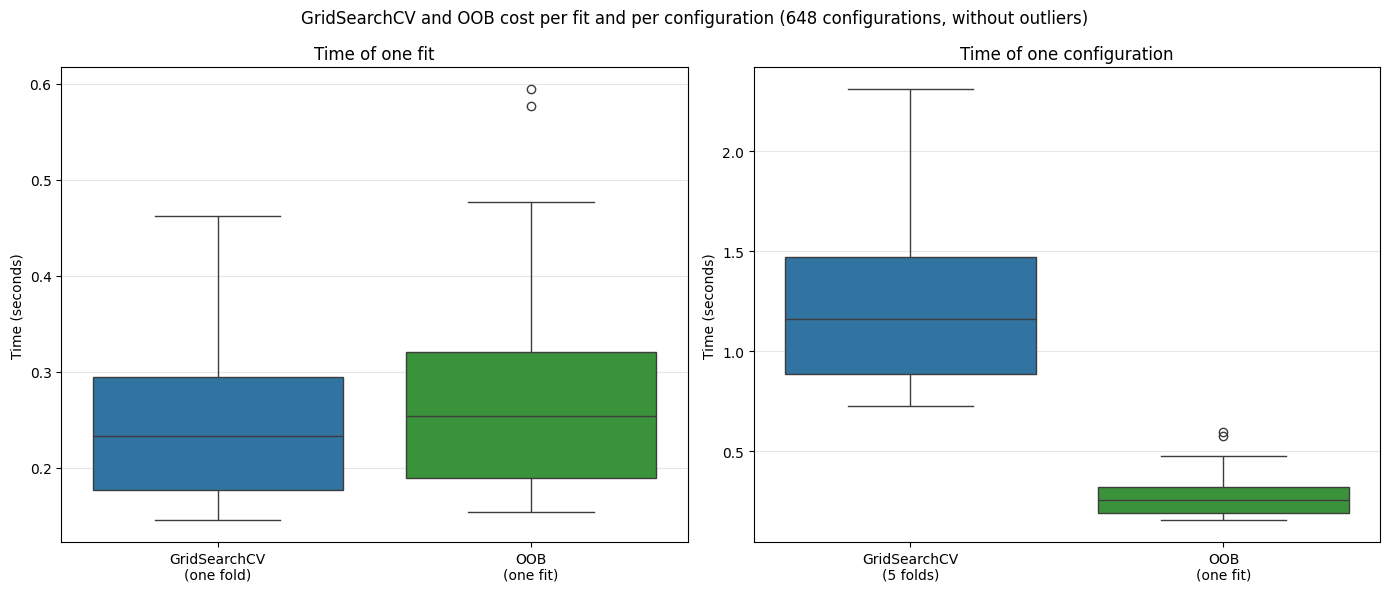

One fit: GridSearchCV (one fold)             0.2325
One fit: OOB                                 0.2540
One configuration: GridSearchCV (5 folds)    1.1625
One configuration: OOB                       0.2540
Name: median (s), dtype: float64


In [27]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

fit_time_df = pd.DataFrame({
    'GridSearchCV\n(one fold)': comparison_plot['grid_fold_time'],
    'OOB\n(one fit)': comparison_plot['oob_time'],
})
sns.boxplot(data=fit_time_df, palette=[paleta[0], paleta[2]], ax=ax[0])
ax[0].set_title('Time of one fit')
ax[0].set_ylabel('Time (seconds)')

config_time_df = pd.DataFrame({
    f'GridSearchCV\n({n_folds} folds)': comparison_plot['grid_config_time'],
    'OOB\n(one fit)': comparison_plot['oob_time'],
})
sns.boxplot(data=config_time_df, palette=[paleta[0], paleta[2]], ax=ax[1])
ax[1].set_title('Time of one configuration')
ax[1].set_ylabel('Time (seconds)')

for a in ax:
    a.grid(axis='y', alpha=0.3)
fig.suptitle(f'GridSearchCV and OOB cost per fit and per configuration ({len(comparison_plot)} configurations, without outliers)')
fig.tight_layout()
plt.show()

medians = pd.concat([fit_time_df.median(), config_time_df.median()]).round(4)
medians.index = ['One fit: GridSearchCV (one fold)', 'One fit: OOB',
                  f'One configuration: GridSearchCV ({n_folds} folds)', 'One configuration: OOB']
print(medians.rename('median (s)'))

The plot compares the time distribution of the 648 configurations at two levels. In both panels, the Y axis shows the time in seconds, and each box corresponds to one strategy: blue for GridSearchCV and green for OOB.

**Left panel: time of one fit**
- One GridSearchCV fold has a median of **0.23 seconds**, and its box ranges from 0.18 to 0.29 seconds. The slowest fold took 0.46 seconds.
- One OOB fit has a median of **0.25 seconds**, and its box ranges from 0.19 to 0.32 seconds. The slowest fit took 0.59 seconds.
- The green box is higher and taller than the blue one: each OOB fit takes somewhat longer, and its time varies more across configurations.

**Right panel: time of one configuration**
- When the 5 folds are added together, the GridSearchCV median rises to **1.16 seconds**, with configurations reaching 2.31 seconds.
- OOB keeps its median of 0.25 seconds, because each configuration is trained only once. The slowest OOB configuration (0.59 seconds) is faster than the GridSearchCV median.
- The middle 50% of GridSearchCV (0.88 to 1.47 seconds) lies well above the OOB box.

**Conclusion:** the plot confirms that OOB is slower per fit (median of 0.25 versus 0.23 seconds, 9.3% more), but much faster per configuration (0.25 versus 1.16 seconds, about 4.6 times less). The advantage of OOB does not come from faster training, but from avoiding the repeated fits of cross-validation.

#### **Plot 2. Total cost breakdown**

The total time of a search can be broken down as **number of fits × mean time per fit**. The plot shows these components in three bar panels, one per component, for each strategy:

- **Mean time per fit:** the average number of seconds taken by one GridSearchCV fold or one OOB fit.
- **Number of fits:** 648 × 5 + 1 in GridSearchCV (the folds plus the final refit) and 648 in OOB.
- **Total time:** the sum of the times of all fits. The total time measured with time.time(), which also includes the internal management of each search, is shown at the base of each bar.

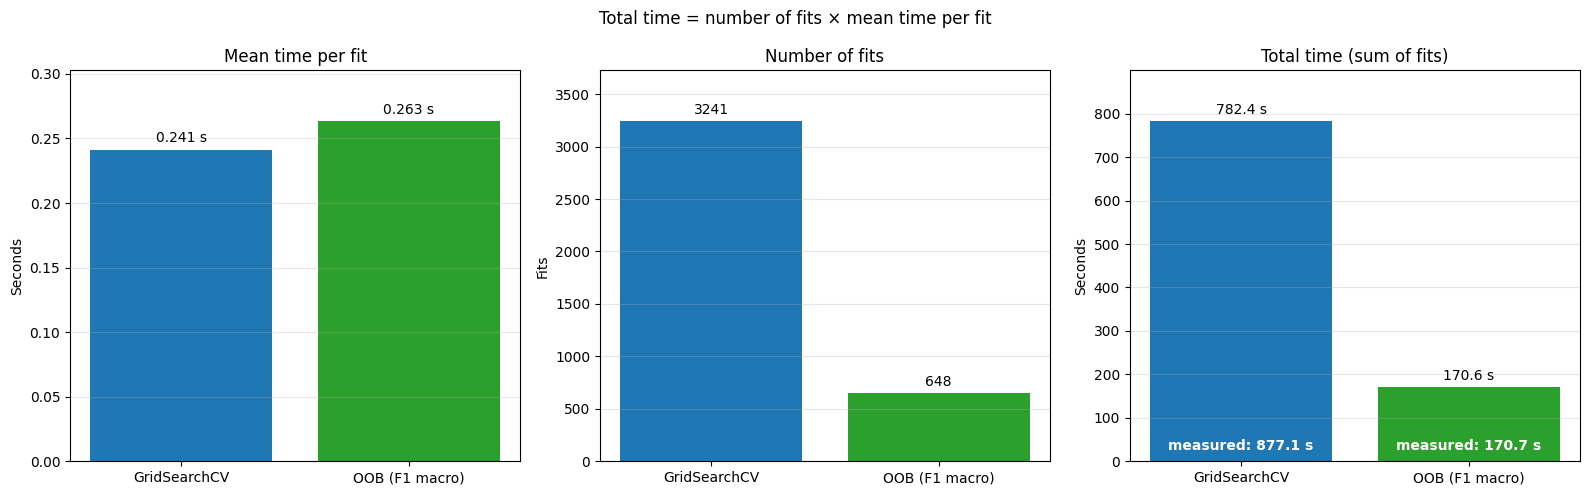

In [28]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))
colors = [paleta[0], paleta[2]]
methods = cost_summary.index

panels = [
    ('mean time per fit (s)', 'Mean time per fit', 'Seconds', '{:.3f} s'),
    ('fits', 'Number of fits', 'Fits', '{:.0f}'),
    ('sum of fits (s)', 'Total time (sum of fits)', 'Seconds', '{:.1f} s'),
]
for a, (column, title, label, fmt) in zip(ax, panels):
    bars = a.bar(methods, cost_summary[column], color=colors)
    a.bar_label(bars, labels=[fmt.format(v) for v in cost_summary[column]], padding=3)
    a.set_title(title)
    a.set_ylabel(label)
    a.margins(y=0.15)
    a.grid(axis='y', alpha=0.3)

for x, measured in enumerate(cost_summary['measured time (s)']):
    ax[2].annotate(f'measured: {measured:.1f} s', (x, 0), xytext=(0, 8),
                   textcoords='offset points', ha='center', color='white', fontweight='bold')

fig.suptitle('Total time = number of fits × mean time per fit')
fig.tight_layout()
plt.show()

The plot breaks down the total cost of each strategy into its two factors, with blue bars for GridSearchCV and green bars for OOB:

- **Mean time per fit (left panel):** OOB takes 0.263 seconds per fit and GridSearchCV 0.241. This is the only component in which OOB is more expensive.
- **Number of fits (center panel):** GridSearchCV performs 3,241 fits and OOB 648, that is, 5 times fewer. The proportion is set by cv=5.
- **Total time (right panel):** the sum of the fits is 782.4 seconds in GridSearchCV and 170.6 seconds in OOB. The measured time, shown at the base of each bar, is 877.1 and 170.7 seconds, respectively.

The total time is the product of the first two panels. GridSearchCV has a cheaper fit but repeats it 5 times per configuration. OOB has a fit that is 9.1% more expensive but performs it only once. The net result is that GridSearchCV took about 5.1 times longer than OOB according to the measured time (877.1 versus 170.7 seconds).

**Conclusion:** the cost of a hyperparameter search depends more on the number of fits than on the time of each fit. The result matches the regression case. In this run, the OOB fit was only 9.1% more expensive than one fold (20.2% in regression) and, therefore, the total advantage was larger (5.1 times compared with 4.6).

## **Classification conclusions**
---
- **The OOB score reduced the search time by about 81%.** Evaluating the 648 configurations took 877.10 seconds with GridSearchCV, 166.84 seconds with OOB accuracy, and 170.73 seconds with OOB macro F1.
- **OOB is slower per fit, but much faster per configuration.** One OOB fit took 0.263 seconds on average, 9.1% more than one GridSearchCV fold (0.241), because it trains on the 800 observations and calculates the out-of-bag predictions. However, GridSearchCV needed 3,241 fits compared with 648.
- **GridSearchCV obtained the best test performance, with small differences.** The test macro F1 was 0.8055 with GridSearchCV, 0.7970 with OOB accuracy, and 0.7882 with OOB macro F1. The largest difference is 1.7 points, and with 31 observations from the minority class in the test set, part of it may be due to the split.
- **The validation estimates are at the same level.** The best mean cross-validation macro F1 was 0.7901 and the best OOB macro F1 was 0.7974.
- **Unlike regression, the OOB metric changed the selection.** Accuracy and macro F1 are not transformations of each other: accuracy preferred configurations with sqrt or log2, and macro F1 preferred max_features=0.75. Even so, the difference between both groups in OOB macro F1 was only 0.0002, and optimizing macro F1 during selection did not improve the test macro F1.
- **All strategies show overfitting.** The best configurations reach a training macro F1 of 1.0 compared with about 0.79 to 0.80 on validation. Within the explored space, performance levels off around a macro F1 of 0.79 to 0.81; improving it may require a different search space, feature engineering, or other algorithms.
- **Limitations:** the results come from a synthetic dataset of 1,000 observations, a single test split of 200 observations (31 from the minority class), and a single machine. Times depend on the hardware and system load and may vary between runs; the proportions between strategies are more stable than the absolute values. In the searches with ties, only one of the tied configurations was evaluated on the test set.

# **Info**
---

**@By:** Steven Bernal

**@Nickname:** Kaiziferr

**@Git:** https://github.com/Kaiziferr